# Difusión condicional · Generación de caras RGB a partir de máscaras

## 0. Fundamento teórico y objetivos

Entrenamos desde cero un modelo que genera **caras RGB de 64×64** a partir de **ocho máscaras binarias de CelebAMask**. Las máscaras describen la distribución espacial de los rasgos. El modelo aprende a completar el color, la iluminación y los detalles visuales a partir de las fotos.

### 0.1 Difusión condicional

Durante el entrenamiento se añade ruido gaussiano a la foto. El U-ViT recibe la foto con ruido, el nivel de ruido y la máscara limpia. Aprende a predecir una cantidad que combina la señal y el ruido, denominada *v*. Durante la generación, se empieza con ruido y se aplica el modelo repetidamente con la misma máscara.

### 0.2 Objetivo de la evaluación

Observamos si la cara generada sigue la forma de la máscara, cuánto puede variar con distintas semillas y cómo responde a cambios concretos en los rasgos. Complementamos estas pruebas con métricas sobre el conjunto de test.

**Créditos del modelo.** El U-ViT y el proceso de difusión se adaptaron de la implementación de **Phil Wang (lucidrains)** en el repositorio `denoising-diffusion-pytorch`. La adaptación incorpora las máscaras de CelebAMask como condición en el entrenamiento y en cada paso del muestreo. [Archivo original](https://github.com/lucidrains/denoising-diffusion-pytorch/blob/main/denoising_diffusion_pytorch/simple_diffusion.py) · [Licencia MIT](https://github.com/lucidrains/denoising-diffusion-pytorch/blob/main/LICENSE)

## 1. Configuración e imports

En Colab, selecciona un entorno con GPU y ejecuta las celdas en orden. El notebook busca el ZIP original en `MyDrive/Practica2/CelebAMask.zip` si aún no existe la caché RGB.

Con `TRAIN_MODEL = False` puedes evaluar el mejor checkpoint directamente. Para entrenar desde cero, usa `TRAIN_MODEL = True` y `RESUME_FROM_BEST = False`. Activa `RUN_TEST_METRICS` para calcular FID, KID y las métricas emparejadas.

Las salidas guardadas corresponden a la ejecución anterior. Vuelve a ejecutar las celdas para actualizarlas.

In [1]:
%pip install -q "einops>=0.6.1" "torchmetrics[image]" torch-fidelity opencv-python-headless

In [4]:
import json
import os
import sys
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 1234
IMG_SIZE = 64
IMAGE_CHANNELS = 3
TOTAL_IMAGES = 30_000
VAL_FRACTION = TEST_FRACTION = 0.05
CLASSES = ("hair", "hat", "l_ear", "r_ear", "l_eye", "r_eye", "nose", "mouth")
N_CLASSES = len(CLASSES)

TRAIN_MODEL = True
RESUME_FROM_BEST = False
EPOCHS = 40  # Épocas adicionales cuando se carga un checkpoint.
BATCH_SIZE = 32
LEARNING_RATE = 2e-4
MODEL_DIM = 32
VIT_DEPTH = 2
SAMPLE_STEPS = 50
SAMPLE_BATCH_SIZE = 16

RUN_TEST_METRICS = True
N_TEST_METRICS = 128  # None usa todo test. Para una prueba rápida, pon 128.
N_EVAL_REPEATS = 1
METRIC_BATCH_SIZE = 32
KID_SUBSET_SIZE = 100

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive")
    DATASET_ZIP = PROJECT_DIR / "CelebAMask.zip"
    DATASET_DIR = Path("/content/dataset")
else:
    PROJECT_DIR = Path(".")
    DATASET_ZIP = PROJECT_DIR / "CelebAMask.zip"
    DATASET_DIR = Path("mg-practica-1-generando-caras/CelebAMask")

CACHE_PATH = PROJECT_DIR / "cache" / f"celebamask_{IMG_SIZE}_rgb.npz"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_desde_cero"
RESULTS_DIR = PROJECT_DIR / "results"
BEST_PATH = CHECKPOINT_DIR / "simple_diffusion_rgb_best.pt"
LAST_PATH = CHECKPOINT_DIR / "simple_diffusion_rgb_last.pt"
METRICS_PATH = RESULTS_DIR / "simple_diffusion_rgb_metrics.json"

torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dispositivo: cuda


## 2. Datos, máscaras y reparto

Cada ejemplo contiene la fotografía original en **RGB** y ocho máscaras binarias alineadas. El ZIP contiene archivos como `images/0.jpg` y `masks/00000_hair.png`. La fotografía se redimensiona a 64×64 y las máscaras se redimensionan mediante vecino más cercano. Cada clase ausente queda a cero. Los ocho canales se conservan de forma independiente.

La caché RGB se crea a partir de los originales. El reparto fijo es **90 % entrenamiento, 5 % validación y 5 % test**. Validación se usa para elegir el checkpoint y test se reserva para la evaluación.

In [5]:
def find_dataset_dir(root):
    for dirpath, dirnames, _ in os.walk(root):
        if "images" in dirnames and "masks" in dirnames:
            return dirpath
    raise FileNotFoundError(f"No se encuentran las carpetas images/ y masks/ dentro de {root}")


def load_from_disk(dataset_dir):
    images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE, IMAGE_CHANNELS), dtype=np.uint8)
    masks = np.zeros((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE, N_CLASSES), dtype=np.uint8)
    mask_dir = os.path.join(dataset_dir, "masks")
    mask_files = set(os.listdir(mask_dir))
    suffixes = tuple(f'_{name}.png' for name in CLASSES)
    if not any(filename.endswith(suffixes) for filename in mask_files):
        raise ValueError(f'No se encontraron máscaras de las ocho clases en {mask_dir}')

    for i in range(TOTAL_IMAGES):
        img_path = os.path.join(dataset_dir, "images", f"{i}.jpg")
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Error para cargar la imagen: {img_path}")
        if img.shape[:2] != (IMG_SIZE, IMG_SIZE):
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        images[i] = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        for c, name in enumerate(CLASSES):
            filename = f"{i:05d}_{name}.png"
            if filename in mask_files:
                m = cv2.imread(os.path.join(mask_dir, filename), cv2.IMREAD_GRAYSCALE)
                if m is None:
                    raise ValueError(f"No se puede leer la máscara {filename}")
                if m.shape != (IMG_SIZE, IMG_SIZE):
                    # vecino más cercano: no mezcla valores de máscara al redimensionar
                    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
                masks[i, ..., c] = m
    return images, masks



t0 = time.perf_counter()
if CACHE_PATH.is_file():
    with np.load(CACHE_PATH, allow_pickle=False) as cache:
        images, masks = cache["images"], cache["masks"]
else:
    # Usa la carpeta ya extraída. Si falta, el ZIP puede contener una carpeta raíz.
    try:
        source_dir = find_dataset_dir(DATASET_DIR)
    except FileNotFoundError:
        if not DATASET_ZIP.is_file():
            raise FileNotFoundError(f"Faltan el dataset en {DATASET_DIR} y el ZIP {DATASET_ZIP}")
        with zipfile.ZipFile(DATASET_ZIP) as archive:
            archive.extractall(DATASET_DIR)
        source_dir = find_dataset_dir(DATASET_DIR)
    images, masks = load_from_disk(source_dir)
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    temp_cache = CACHE_PATH.with_suffix(".tmp.npz")
    np.savez_compressed(temp_cache, images=images, masks=masks)
    temp_cache.replace(CACHE_PATH)

expected = (TOTAL_IMAGES, IMG_SIZE, IMG_SIZE)
if images.shape != (*expected, IMAGE_CHANNELS) or masks.shape != (*expected, N_CLASSES):
    raise ValueError(f"Caché incompatible: {images.shape=} y {masks.shape=}")
if images.dtype != np.uint8 or masks.dtype != np.uint8:
    raise ValueError("La caché debe contener caras RGB y máscaras uint8")
print(f"Pares cargados: {len(images):,} en {time.perf_counter() - t0:.1f} s")

Pares cargados: 30,000 en 5.5 s


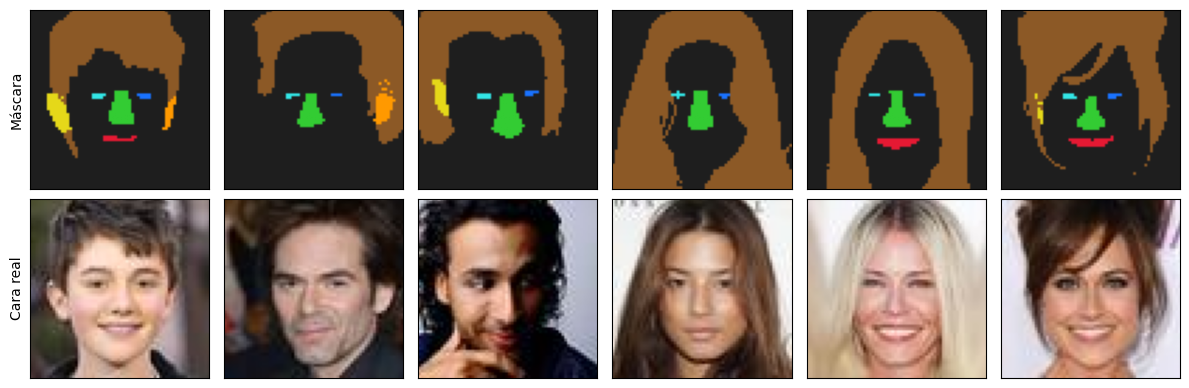

In [6]:
# Paleta para dibujar las máscaras (izquierda y derecha con colores distintos)
PALETTE = np.array([
    [0.12, 0.12, 0.12],   # sin clase
    [0.55, 0.35, 0.15],   # hair
    [0.60, 0.20, 0.80],   # hat
    [1.00, 0.60, 0.00],   # l_ear
    [0.90, 0.85, 0.10],   # r_ear
    [0.10, 0.45, 1.00],   # l_eye
    [0.20, 0.90, 0.90],   # r_eye
    [0.20, 0.80, 0.20],   # nose
    [0.90, 0.10, 0.20],   # mouth
])


def mask_to_color(mask):
    mask = np.asarray(mask)
    if mask.dtype != np.uint8:
        mask = (np.clip(mask, 0.0, 1.0) * 255).astype(np.uint8)
    labels = np.where(mask.max(axis=-1) > 127, mask.argmax(axis=-1) + 1, 0)
    return PALETTE[labels]


def show_grid(rows, labels, title=None):
    ncols = len(rows[0])
    fig, axes = plt.subplots(len(rows), ncols, figsize=(2 * ncols, 2 * len(rows)), squeeze=False)
    for row, label, ax_row in zip(rows, labels, axes):
        ax_row[0].set_ylabel(label)
        for img, ax in zip(row, ax_row):
            ax.imshow(img)
            ax.set_xticks([])
            ax.set_yticks([])
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

preview = np.random.default_rng(42).choice(len(images), size=6, replace=False)
show_grid([[mask_to_color(masks[i]) for i in preview], images[preview]], ["Máscara", "Cara real"])

In [7]:
# Split reproducible 90 / 5 / 5
rng = np.random.default_rng(SEED)
indices = rng.permutation(TOTAL_IMAGES)
n_val = int(VAL_FRACTION * TOTAL_IMAGES)
n_test = int(TEST_FRACTION * TOTAL_IMAGES)
val_idx = indices[:n_val]
test_idx = indices[n_val:n_val + n_test]
train_idx = indices[n_val + n_test:]

img_train, mask_train = images[train_idx], masks[train_idx]
img_val, mask_val = images[val_idx], masks[val_idx]
img_test, mask_test = images[test_idx], masks[test_idx]
del images, masks

print(f"Entrenamiento: {img_train.shape} | {mask_train.shape}")
print(f"Validación:    {img_val.shape} | {mask_val.shape}")
print(f"Test:          {img_test.shape} | {mask_test.shape}")

Entrenamiento: (27000, 64, 64, 3) | (27000, 64, 64, 8)
Validación:    (1500, 64, 64, 3) | (1500, 64, 64, 8)
Test:          (1500, 64, 64, 3) | (1500, 64, 64, 8)


### 2.1 Preparación y aumento de datos

Las fotos pasan del formato `(B, H, W, 3)` al formato `(B, 3, H, W)` en `[0, 1]`. La difusión las escala internamente a `[-1, 1]`. La máscara pasa a `(B, 8, H, W)` y se mantiene en `[0, 1]`. En entrenamiento, el volteo horizontal se aplica a la foto y a la máscara juntas, intercambiando los canales de ojos y orejas izquierdos y derechos.

In [8]:
FLIP_PERM = [CLASSES.index(name) for name in
             ("hair", "hat", "r_ear", "l_ear", "r_eye", "l_eye", "nose", "mouth")]


class FaceMaskDataset(Dataset):
    def __init__(self, faces, masks, augment=False):
        self.faces = faces
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.faces)

    def __getitem__(self, index):
        face = torch.from_numpy(self.faces[index]).permute(2, 0, 1).float().div_(255)
        mask = torch.from_numpy(self.masks[index]).permute(2, 0, 1).float().div_(255)
        if self.augment and torch.rand(()) < 0.5:
            face = face.flip(-1)
            mask = mask[FLIP_PERM].flip(-1)
        return mask, face


train_loader = DataLoader(
    FaceMaskDataset(img_train, mask_train, augment=True), batch_size=BATCH_SIZE,
    shuffle=True, generator=torch.Generator().manual_seed(SEED), pin_memory=DEVICE.type == "cuda",
)
val_loader = DataLoader(
    FaceMaskDataset(img_val, mask_val), batch_size=BATCH_SIZE,
    pin_memory=DEVICE.type == "cuda",
)

## 3. Arquitectura del U-ViT

El modelo combina **difusión gaussiana condicionada por máscaras** con un **U-ViT**. El U-ViT estima cómo quitar ruido en un paso. La clase *GaussianDiffusion* controla cuánto ruido se añade durante el entrenamiento y cómo se actualiza la imagen durante la generación.

### 3.1 Entradas y condicionamiento por la máscara

En las formas siguientes, $B$ es el número de ejemplos del lote. PyTorch ordena los tensores de imagen como lote, canales, alto y ancho.

| Entrada | Forma | Qué representa |
| --- | --- | --- |
| Imagen con ruido $x_t$ | $(B, 3, 64, 64)$ | El estado actual de la imagen RGB |
| Máscara $m$ | $(B, 8, 64, 64)$ | Pelo, gorro, oreja izquierda, oreja derecha, ojo izquierdo, ojo derecho, nariz y boca |
| Nivel de ruido | $(B,)$ | Un valor *log_snr* por ejemplo, el logaritmo de la relación señal-ruido |

La imagen y la máscara están alineadas píxel a píxel. Se concatenan por canales al comienzo del U-ViT para formar un tensor de **11 canales**, tres de imagen RGB y ocho de máscara. Una convolución de $7\times7$ con relleno de 3 píxeles lo proyecta a **32 canales** y conserva la resolución de $64\times64$. A partir de ahí, las capas y las conexiones de salto transportan las características que contienen información de la máscara.

### 3.2 Encoder

Cada etapa aplica **dos bloques residuales**, **atención lineal** y **reducción de resolución**. Cada bloque residual contiene dos convoluciones de $3\times3$ con RMSNorm y SiLU. Su salida se suma a la entrada del bloque, que pasa por una convolución de $1\times1$ cuando hay que ajustar el número de canales.

Antes de reducir, cada etapa guarda dos mapas para el decoder. El primero sale del primer bloque residual y el segundo, de la atención lineal. Esta atención mezcla información de distintas posiciones sin construir una matriz que compare todas las posiciones entre sí.

La reducción reorganiza cada región de $2\times2$ en la dimensión de canales y usa una convolución de $1\times1$ para fijar el número de canales de salida.

| Etapa | Entrada $C\times H\times W$ | Salida tras reducir |
| --- | --- | --- |
| 1 | $32\times64\times64$ | $32\times32\times32$ |
| 2 | $32\times32\times32$ | $64\times16\times16$ |
| 3 | $64\times16\times16$ | $128\times8\times8$ |
| 4 | $128\times8\times8$ | $256\times4\times4$ |

### 3.3 Transformer en el cuello de botella

El mapa de $256\times4\times4$ se reorganiza como **16 tokens de 256 características**, uno por posición espacial del mapa reducido. El modelo usa **dos capas Transformer**. Cada capa aplica autoatención global de **cuatro cabezas** y una red *feed-forward* con conexiones residuales.

Cada token puede consultar los demás. Eso permite relacionar regiones alejadas de la cara antes de reconstruirla. Aplicar la atención global en el mapa de $4\times4$ limita el cálculo a 16 posiciones. Después, los tokens se reorganizan otra vez como un mapa de $256\times4\times4$.

### 3.4 Decoder y salida

El decoder duplica la resolución en cada etapa mediante una convolución de $1\times1$, una activación SiLU y *PixelShuffle*, que reorganiza canales como posiciones espaciales. Luego concatena los dos mapas guardados de la resolución correspondiente, uno antes de cada bloque residual, y aplica atención lineal al final de la etapa.

El decoder recorre las resoluciones de $4\times4$ a $8\times8$, $16\times16$, $32\times32$ y $64\times64$. Las conexiones de salto recuperan información espacial que sería difícil conservar solo en el cuello de botella, como la posición de los ojos o el contorno de la boca.

Al final se concatena también el mapa de la primera convolución. Un bloque residual y una convolución de $1\times1$ producen la salida **$(B,3,64,64)$**. Los tres canales contienen la predicción $\hat v$ con la que la difusión estima la imagen limpia.

### 3.5 Cómo se incorpora el nivel de ruido

El U-ViT convierte el *log_snr* de cada ejemplo en un **vector de 128 valores** con funciones sinusoidales de frecuencias aprendidas y una pequeña red de capas lineales. Cada bloque residual proyecta ese vector para calcular una escala y un desplazamiento por canal. La red *feed-forward* de cada capa Transformer hace lo mismo para sus características internas.

La modulación se aplica como $h(1+\text{escala})+\text{desplazamiento}$. Así, la máscara indica **dónde** deben aparecer los rasgos y el nivel de ruido informa a la red de **cuánta señal queda** en la imagen.

### 3.6 Cómo se usa al entrenar y al generar

- **Entrenamiento.** Se elige un nivel de ruido por ejemplo y se construye $x_t=\alpha_t x_0+\sigma_t\epsilon$, donde $x_0$ es la cara real y $\epsilon$ es ruido gaussiano. La máscara permanece limpia. El U-ViT predice $v=\alpha_t\epsilon-\sigma_t x_0$ en una sola pasada por lote. La sección 4 detalla la pérdida MSE ponderada mediante Min-SNR.
- **Generación.** Se parte de ruido gaussiano y se usa **la misma máscara en todos los pasos**. La difusión estima la imagen limpia mediante $\hat{x}_0=\alpha_t x_t-\sigma_t\hat v$ y avanza al siguiente nivel de ruido. El notebook hace **50 pasos por defecto**. Cambiar la semilla permite generar distintas caras con la misma máscara.

In [9]:
# Adaptado de lucidrains/denoising-diffusion-pytorch (simple_diffusion.py).
# Copyright (c) 2020 Phil Wang. Licencia MIT al final del notebook.

import math
from functools import wraps

import torch
from torch import sqrt
from torch import nn, einsum
import torch.nn.functional as F
from torch.special import expm1
from torch.amp import autocast

from einops import rearrange, repeat, reduce, pack, unpack
from einops.layers.torch import Rearrange

# helpers

def exists(val):
    return val is not None

def identity(t):
    return t

def is_lambda(f):
    return callable(f) and f.__name__ == "<lambda>"

def default(val, d):
    if exists(val):
        return val
    return d() if is_lambda(d) else d

def cast_tuple(t, l = 1):
    return ((t,) * l) if not isinstance(t, tuple) else t

def append_dims(t, dims):
    shape = t.shape
    return t.reshape(*shape, *((1,) * dims))

def l2norm(t):
    return F.normalize(t, dim = -1)

# u-vit related functions and modules

class Upsample(nn.Module):
    def __init__(
        self,
        dim,
        dim_out = None,
        factor = 2
    ):
        super().__init__()
        self.factor = factor
        self.factor_squared = factor ** 2

        dim_out = default(dim_out, dim)
        conv = nn.Conv2d(dim, dim_out * self.factor_squared, 1)

        self.net = nn.Sequential(
            conv,
            nn.SiLU(),
            nn.PixelShuffle(factor)
        )

        self.init_conv_(conv)

    def init_conv_(self, conv):
        o, i, h, w = conv.weight.shape
        conv_weight = torch.empty(o // self.factor_squared, i, h, w)
        nn.init.kaiming_uniform_(conv_weight)
        conv_weight = repeat(conv_weight, 'o ... -> (o r) ...', r = self.factor_squared)

        conv.weight.data.copy_(conv_weight)
        nn.init.zeros_(conv.bias.data)

    def forward(self, x):
        return self.net(x)

def Downsample(
    dim,
    dim_out = None,
    factor = 2
):
    return nn.Sequential(
        Rearrange('b c (h p1) (w p2) -> b (c p1 p2) h w', p1 = factor, p2 = factor),
        nn.Conv2d(dim * (factor ** 2), default(dim_out, dim), 1)
    )

class RMSNorm(nn.Module):
    def __init__(self, dim, scale = True, normalize_dim = 2):
        super().__init__()
        self.g = nn.Parameter(torch.ones(dim)) if scale else 1

        self.scale = scale
        self.normalize_dim = normalize_dim

    def forward(self, x):
        normalize_dim = self.normalize_dim
        scale = append_dims(self.g, x.ndim - self.normalize_dim - 1) if self.scale else 1
        return F.normalize(x, dim = normalize_dim) * scale * (x.shape[normalize_dim] ** 0.5)

# sinusoidal positional embeds

class LearnedSinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert (dim % 2) == 0
        half_dim = dim // 2
        self.weights = nn.Parameter(torch.randn(half_dim))

    def forward(self, x):
        x = rearrange(x, 'b -> b 1')
        freqs = x * rearrange(self.weights, 'd -> 1 d') * 2 * math.pi
        fouriered = torch.cat((freqs.sin(), freqs.cos()), dim = -1)
        fouriered = torch.cat((x, fouriered), dim = -1)
        return fouriered

# building block modules

class Block(nn.Module):
    def __init__(self, dim, dim_out):
        super().__init__()
        self.proj = nn.Conv2d(dim, dim_out, 3, padding = 1)
        self.norm = RMSNorm(dim_out, normalize_dim = 1)
        self.act = nn.SiLU()

    def forward(self, x, scale_shift = None):
        x = self.proj(x)
        x = self.norm(x)

        if exists(scale_shift):
            scale, shift = scale_shift
            x = x * (scale + 1) + shift

        x = self.act(x)
        return x

class ResnetBlock(nn.Module):
    def __init__(self, dim, dim_out, *, time_emb_dim = None):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_emb_dim, dim_out * 2)
        ) if exists(time_emb_dim) else None

        self.block1 = Block(dim, dim_out)
        self.block2 = Block(dim_out, dim_out)
        self.res_conv = nn.Conv2d(dim, dim_out, 1) if dim != dim_out else nn.Identity()

    def forward(self, x, time_emb = None):

        scale_shift = None
        if exists(self.mlp) and exists(time_emb):
            time_emb = self.mlp(time_emb)
            time_emb = rearrange(time_emb, 'b c -> b c 1 1')
            scale_shift = time_emb.chunk(2, dim = 1)

        h = self.block1(x, scale_shift = scale_shift)

        h = self.block2(h)

        return h + self.res_conv(x)

class LinearAttention(nn.Module):
    def __init__(self, dim, heads = 4, dim_head = 32):
        super().__init__()
        self.scale = dim_head ** -0.5
        self.heads = heads
        hidden_dim = dim_head * heads

        self.norm = RMSNorm(dim, normalize_dim = 1)
        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias = False)

        self.to_out = nn.Sequential(
            nn.Conv2d(hidden_dim, dim, 1),
            RMSNorm(dim, normalize_dim = 1)
        )

    def forward(self, x):
        residual = x

        b, c, h, w = x.shape

        x = self.norm(x)

        qkv = self.to_qkv(x).chunk(3, dim = 1)
        q, k, v = map(lambda t: rearrange(t, 'b (h c) x y -> b h c (x y)', h = self.heads), qkv)

        q = q.softmax(dim = -2)
        k = k.softmax(dim = -1)

        q = q * self.scale

        context = torch.einsum('b h d n, b h e n -> b h d e', k, v)

        out = torch.einsum('b h d e, b h d n -> b h e n', context, q)
        out = rearrange(out, 'b h c (x y) -> b (h c) x y', h = self.heads, x = h, y = w)

        return self.to_out(out) + residual

class Attention(nn.Module):
    def __init__(self, dim, heads = 4, dim_head = 32, scale = 8, dropout = 0.):
        super().__init__()
        self.scale = scale
        self.heads = heads
        hidden_dim = dim_head * heads

        self.norm = RMSNorm(dim)

        self.attn_dropout = nn.Dropout(dropout)
        self.to_qkv = nn.Linear(dim, hidden_dim * 3, bias = False)

        self.q_scale = nn.Parameter(torch.ones(dim_head))
        self.k_scale = nn.Parameter(torch.ones(dim_head))

        self.to_out = nn.Linear(hidden_dim, dim, bias = False)

    def forward(self, x):
        x = self.norm(x)

        qkv = self.to_qkv(x).chunk(3, dim = -1)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h = self.heads), qkv)

        q, k = map(l2norm, (q, k))

        q = q * self.q_scale
        k = k * self.k_scale

        sim = einsum('b h i d, b h j d -> b h i j', q, k) * self.scale

        attn = sim.softmax(dim = -1)
        attn = self.attn_dropout(attn)

        out = einsum('b h i j, b h j d -> b h i d', attn, v)

        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)

class FeedForward(nn.Module):
    def __init__(
        self,
        dim,
        cond_dim,
        mult = 4,
        dropout = 0.
    ):
        super().__init__()
        self.norm = RMSNorm(dim, scale = False)
        dim_hidden = dim * mult

        self.to_scale_shift = nn.Sequential(
            nn.SiLU(),
            nn.Linear(cond_dim, dim_hidden * 2),
            Rearrange('b d -> b 1 d')
        )

        to_scale_shift_linear = self.to_scale_shift[-2]
        nn.init.zeros_(to_scale_shift_linear.weight)
        nn.init.zeros_(to_scale_shift_linear.bias)

        self.proj_in = nn.Sequential(
            nn.Linear(dim, dim_hidden, bias = False),
            nn.SiLU()
        )

        self.proj_out = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(dim_hidden, dim, bias = False)
        )

    def forward(self, x, t):
        x = self.norm(x)
        x = self.proj_in(x)

        scale, shift = self.to_scale_shift(t).chunk(2, dim = -1)
        x = x * (scale + 1) + shift

        return self.proj_out(x)

# vit

class Transformer(nn.Module):
    def __init__(
        self,
        dim,
        time_cond_dim,
        depth,
        dim_head = 32,
        heads = 4,
        ff_mult = 4,
        dropout = 0.,
    ):
        super().__init__()

        self.layers = nn.ModuleList([])
        for _ in range(depth):
            self.layers.append(nn.ModuleList([
                Attention(dim = dim, dim_head = dim_head, heads = heads, dropout = dropout),
                FeedForward(dim = dim, mult = ff_mult, cond_dim = time_cond_dim, dropout = dropout)
            ]))

    def forward(self, x, t):
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x, t) + x

        return x

In [10]:
class UViT(nn.Module):
    def __init__(
        self,
        dim,
        init_dim = None,
        out_dim = None,
        dim_mults = (1, 2, 4, 8),
        downsample_factor = 2,
        channels = 3,
        vit_depth = 6,
        vit_dropout = 0.2,
        attn_dim_head = 32,
        attn_heads = 4,
        ff_mult = 4,
        learned_sinusoidal_dim = 16,
        init_img_transform: callable = None,
        final_img_itransform: callable = None,
        patch_size = 1,
        dual_patchnorm = False,
        mask_channels = 0
    ):
        super().__init__()

        # for initial dwt transform (or whatever transform researcher wants to try here)

        if exists(init_img_transform) and exists(final_img_itransform):
            init_shape = torch.Size((1, channels, 32, 32))
            mock_tensor = torch.randn(init_shape)
            assert final_img_itransform(init_img_transform(mock_tensor)).shape == init_shape

        self.init_img_transform = default(init_img_transform, identity)
        self.final_img_itransform = default(final_img_itransform, identity)

        self.mask_channels = mask_channels
        in_channels = channels + mask_channels

        init_dim = default(init_dim, dim)
        self.init_conv = nn.Conv2d(in_channels, init_dim, 7, padding = 3)

        # whether to do initial patching, as alternative to dwt

        self.unpatchify = identity

        patch_channels = in_channels * (patch_size ** 2)
        self.out_dim = default(out_dim, channels)
        output_channels = self.out_dim * (patch_size ** 2)
        needs_patch = patch_size > 1

        if needs_patch:
            if not dual_patchnorm:
                self.init_conv = nn.Conv2d(in_channels, init_dim, patch_size, stride = patch_size)
            else:
                self.init_conv = nn.Sequential(
                    Rearrange('b c (h p1) (w p2) -> b h w (c p1 p2)', p1 = patch_size, p2 = patch_size),
                    nn.LayerNorm(patch_channels),
                    nn.Linear(patch_channels, init_dim),
                    nn.LayerNorm(init_dim),
                    Rearrange('b h w c -> b c h w')
                )

            self.unpatchify = nn.ConvTranspose2d(output_channels, self.out_dim, patch_size, stride = patch_size)

        # determine dimensions

        dims = [init_dim, *map(lambda m: dim * m, dim_mults)]
        in_out = list(zip(dims[:-1], dims[1:]))

        # time embeddings

        time_dim = dim * 4

        sinu_pos_emb = LearnedSinusoidalPosEmb(learned_sinusoidal_dim)
        fourier_dim = learned_sinusoidal_dim + 1

        self.time_mlp = nn.Sequential(
            sinu_pos_emb,
            nn.Linear(fourier_dim, time_dim),
            nn.GELU(),
            nn.Linear(time_dim, time_dim)
        )

        # downsample factors

        downsample_factor = cast_tuple(downsample_factor, len(dim_mults))
        assert len(downsample_factor) == len(dim_mults)

        # layers

        self.downs = nn.ModuleList([])
        self.ups = nn.ModuleList([])
        num_resolutions = len(in_out)

        for ind, ((dim_in, dim_out), factor) in enumerate(zip(in_out, downsample_factor)):
            is_last = ind >= (num_resolutions - 1)

            self.downs.append(nn.ModuleList([
                ResnetBlock(dim_in, dim_in, time_emb_dim = time_dim),
                ResnetBlock(dim_in, dim_in, time_emb_dim = time_dim),
                LinearAttention(dim_in),
                Downsample(dim_in, dim_out, factor = factor)
            ]))

        mid_dim = dims[-1]

        self.vit = Transformer(
            dim = mid_dim,
            time_cond_dim = time_dim,
            depth = vit_depth,
            dim_head = attn_dim_head,
            heads = attn_heads,
            ff_mult = ff_mult,
            dropout = vit_dropout
        )

        for ind, ((dim_in, dim_out), factor) in enumerate(zip(reversed(in_out), reversed(downsample_factor))):
            is_last = ind == (len(in_out) - 1)

            self.ups.append(nn.ModuleList([
                Upsample(dim_out, dim_in, factor = factor),
                ResnetBlock(dim_in * 2, dim_in, time_emb_dim = time_dim),
                ResnetBlock(dim_in * 2, dim_in, time_emb_dim = time_dim),
                LinearAttention(dim_in),
            ]))

        self.final_res_block = ResnetBlock(init_dim * 2, init_dim, time_emb_dim = time_dim)
        self.final_conv = nn.Conv2d(init_dim, output_channels, 1)

    def forward(self, x, time, mask=None):
        x = self.init_img_transform(x)
        if self.mask_channels:
            expected = (x.shape[0], self.mask_channels, *x.shape[-2:])
            if mask is None or mask.shape != expected:
                raise ValueError(f'La máscara debe tener forma {expected}')
            x = torch.cat((x, mask.to(device=x.device, dtype=x.dtype)), dim=1)
        elif mask is not None:
            raise ValueError('Configura mask_channels en el UViT para usar máscaras')

        x = self.init_conv(x)
        r = x.clone()

        t = self.time_mlp(time)

        h = []

        for block1, block2, attn, downsample in self.downs:
            x = block1(x, t)
            h.append(x)

            x = block2(x, t)
            x = attn(x)
            h.append(x)

            x = downsample(x)

        x = rearrange(x, 'b c h w -> b h w c')
        x, ps = pack([x], 'b * c')

        x = self.vit(x, t)

        x, = unpack(x, ps, 'b * c')
        x = rearrange(x, 'b h w c -> b c h w')

        for upsample, block1, block2, attn in self.ups:
            x = upsample(x)

            x = torch.cat((x, h.pop()), dim = 1)
            x = block1(x, t)

            x = torch.cat((x, h.pop()), dim = 1)
            x = block2(x, t)
            x = attn(x)

        x = torch.cat((x, r), dim = 1)

        x = self.final_res_block(x, t)
        x = self.final_conv(x)

        x = self.unpatchify(x)
        return self.final_img_itransform(x)

In [11]:
def normalize_to_neg_one_to_one(img):
    return img * 2 - 1

def unnormalize_to_zero_to_one(t):
    return (t + 1) * 0.5

# diffusion helpers

def right_pad_dims_to(x, t):
    padding_dims = x.ndim - t.ndim
    if padding_dims <= 0:
        return t
    return t.view(*t.shape, *((1,) * padding_dims))

# logsnr schedules and shifting / interpolating decorators
# only cosine for now

def log(t, eps = 1e-20):
    return torch.log(t.clamp(min = eps))

def logsnr_schedule_cosine(t, logsnr_min = -15, logsnr_max = 15):
    t_min = math.atan(math.exp(-0.5 * logsnr_max))
    t_max = math.atan(math.exp(-0.5 * logsnr_min))
    return -2 * log(torch.tan(t_min + t * (t_max - t_min)))

def logsnr_schedule_shifted(fn, image_d, noise_d):
    shift = 2 * math.log(noise_d / image_d)
    @wraps(fn)
    def inner(*args, **kwargs):
        nonlocal shift
        return fn(*args, **kwargs) + shift
    return inner

def logsnr_schedule_interpolated(fn, image_d, noise_d_low, noise_d_high):
    logsnr_low_fn = logsnr_schedule_shifted(fn, image_d, noise_d_low)
    logsnr_high_fn = logsnr_schedule_shifted(fn, image_d, noise_d_high)

    @wraps(fn)
    def inner(t, *args, **kwargs):
        nonlocal logsnr_low_fn
        nonlocal logsnr_high_fn
        return t * logsnr_low_fn(t, *args, **kwargs) + (1 - t) * logsnr_high_fn(t, *args, **kwargs)

    return inner

# main gaussian diffusion class

class GaussianDiffusion(nn.Module):
    def __init__(
        self,
        model: UViT,
        *,
        image_size,
        channels = 3,
        pred_objective = 'v',
        noise_schedule = logsnr_schedule_cosine,
        noise_d = None,
        noise_d_low = None,
        noise_d_high = None,
        num_sample_steps = 500,
        clip_sample_denoised = True,
        min_snr_loss_weight = True,
        min_snr_gamma = 5
    ):
        super().__init__()
        assert pred_objective in {'v', 'eps'}, 'whether to predict v-space (progressive distillation paper) or noise'

        self.model = model

        # image dimensions

        self.channels = channels
        self.image_size = image_size

        # training objective

        self.pred_objective = pred_objective

        # noise schedule

        assert not all([*map(exists, (noise_d, noise_d_low, noise_d_high))]), 'you must either set noise_d for shifted schedule, or noise_d_low and noise_d_high for shifted and interpolated schedule'

        # determine shifting or interpolated schedules

        self.log_snr = noise_schedule

        if exists(noise_d):
            self.log_snr = logsnr_schedule_shifted(self.log_snr, image_size, noise_d)

        if exists(noise_d_low) or exists(noise_d_high):
            assert exists(noise_d_low) and exists(noise_d_high), 'both noise_d_low and noise_d_high must be set'

            self.log_snr = logsnr_schedule_interpolated(self.log_snr, image_size, noise_d_low, noise_d_high)

        # sampling

        self.num_sample_steps = num_sample_steps
        self.clip_sample_denoised = clip_sample_denoised

        # loss weight

        self.min_snr_loss_weight = min_snr_loss_weight
        self.min_snr_gamma = min_snr_gamma

    @property
    def device(self):
        return next(self.model.parameters()).device

    def p_mean_variance(self, x, time, time_next, mask=None):

        log_snr = self.log_snr(time)
        log_snr_next = self.log_snr(time_next)
        c = -expm1(log_snr - log_snr_next)

        squared_alpha, squared_alpha_next = log_snr.sigmoid(), log_snr_next.sigmoid()
        squared_sigma, squared_sigma_next = (-log_snr).sigmoid(), (-log_snr_next).sigmoid()

        alpha, sigma, alpha_next = map(sqrt, (squared_alpha, squared_sigma, squared_alpha_next))

        batch_log_snr = repeat(log_snr, ' -> b', b = x.shape[0])
        pred = self.model(x, batch_log_snr, mask)

        if self.pred_objective == 'v':
            x_start = alpha * x - sigma * pred

        elif self.pred_objective == 'eps':
            x_start = (x - sigma * pred) / alpha

        if self.clip_sample_denoised:
            x_start.clamp_(-1., 1.)

        model_mean = alpha_next * (x * (1 - c) / alpha + c * x_start)

        posterior_variance = squared_sigma_next * c

        return model_mean, posterior_variance

    # sampling related functions

    @torch.no_grad()
    def p_sample(self, x, time, time_next, mask=None, generator=None, final=False):
        mean, variance = self.p_mean_variance(x, time, time_next, mask)
        if final:
            return mean

        noise = torch.randn(x.shape, device=x.device, dtype=x.dtype, generator=generator)
        return mean + sqrt(variance) * noise

    @torch.no_grad()
    def p_sample_loop(self, shape, mask=None, generator=None, steps=None):
        num_steps = self.num_sample_steps if steps is None else steps
        if num_steps < 1:
            raise ValueError('El muestreo necesita al menos un paso')
        img = torch.randn(shape, device=self.device, generator=generator)
        times = torch.linspace(1., 0., num_steps + 1, device=self.device)

        for i in range(num_steps):
            img = self.p_sample(img, times[i], times[i + 1], mask, generator, final=i + 1 == num_steps)

        img.clamp_(-1., 1.)
        img = unnormalize_to_zero_to_one(img)
        return img

    @torch.no_grad()
    def sample(self, batch_size=16, *, mask=None, generator=None, steps=None):
        if mask is not None:
            mask = mask.to(self.device)
            batch_size = len(mask)
        shape = (batch_size, self.channels, self.image_size, self.image_size)
        return self.p_sample_loop(shape, mask, generator, steps)

    # training related functions - noise prediction

    @autocast('cuda', enabled = False)
    def q_sample(self, x_start, times, noise = None):
        noise = default(noise, lambda: torch.randn_like(x_start))

        log_snr = self.log_snr(times)

        log_snr_padded = right_pad_dims_to(x_start, log_snr)
        alpha, sigma = sqrt(log_snr_padded.sigmoid()), sqrt((-log_snr_padded).sigmoid())
        x_noised =  x_start * alpha + noise * sigma

        return x_noised, log_snr

    def p_losses(self, x_start, times, noise=None, loss_reduction='mean', mask=None):
        noise = default(noise, lambda: torch.randn_like(x_start))

        x, log_snr = self.q_sample(x_start = x_start, times = times, noise = noise)
        model_out = self.model(x, log_snr, mask)

        if self.pred_objective == 'v':
            padded_log_snr = right_pad_dims_to(x, log_snr)
            alpha, sigma = padded_log_snr.sigmoid().sqrt(), (-padded_log_snr).sigmoid().sqrt()
            target = alpha * noise - sigma * x_start

        elif self.pred_objective == 'eps':
            target = noise

        loss = F.mse_loss(model_out, target, reduction = 'none')

        loss = reduce(loss, 'b ... -> b', 'mean')

        snr = log_snr.exp()

        maybe_clip_snr = snr.clone()
        if self.min_snr_loss_weight:
            maybe_clip_snr.clamp_(max = self.min_snr_gamma)

        if self.pred_objective == 'v':
            loss_weight = maybe_clip_snr / (snr + 1)

        elif self.pred_objective == 'eps':
            loss_weight = maybe_clip_snr / snr

        losses = loss * loss_weight

        if loss_reduction == 'none':
            return losses

        return losses.mean()

    def forward(self, img, mask=None, *, times=None, noise=None):
        expected = (self.channels, self.image_size, self.image_size)
        if img.ndim != 4 or img.shape[1:] != expected:
            raise ValueError(f'Cada cara debe tener forma {expected}')

        img = normalize_to_neg_one_to_one(img)
        if times is None:
            times = torch.rand(img.shape[0], device=img.device)
        return self.p_losses(img, times, noise=noise, mask=mask)

In [12]:
MODEL_CONFIG = {
    "image_size": IMG_SIZE,
    "channels": IMAGE_CHANNELS,
    "classes": CLASSES,
    "dim": MODEL_DIM,
    "vit_depth": VIT_DEPTH,
}

def build_diffusion():
    model = UViT(
        dim=MODEL_DIM, channels=IMAGE_CHANNELS, mask_channels=N_CLASSES,
        out_dim=IMAGE_CHANNELS, vit_depth=VIT_DEPTH, patch_size=1,
    )
    return GaussianDiffusion(model, image_size=IMG_SIZE, channels=IMAGE_CHANNELS, num_sample_steps=SAMPLE_STEPS)


diffusion = build_diffusion().to(DEVICE)
print(f"Parámetros entrenables: {sum(p.numel() for p in diffusion.parameters()):,}")

Parámetros entrenables: 4,917,931


## 4. Pérdida, optimizador y entrenamiento

Para cada cara se elige un nivel de ruido y se construye $x_t = \alpha_t x_0 + \sigma_t \epsilon$. El U-ViT predice $v = \alpha_t \epsilon - \sigma_t x_0$. El código aplica MSE con ponderación Min-SNR en los tres canales de la imagen.

Usamos AdamW y precisión mixta en CUDA. Al terminar cada época se guarda el último checkpoint RGB y se actualiza el mejor si baja la pérdida de validación. Para que el criterio sea comparable entre épocas, la validación reutiliza la misma secuencia de niveles de ruido y de muestras gaussianas. El checkpoint con menor pérdida de validación se usa para generar las caras de test.

Al continuar desde el mejor checkpoint, se recuperan sus pesos, la numeración y el historial. Los checkpoints nuevos guardan el estado de AdamW y de la precisión mixta. Si cargas un checkpoint anterior que solo guarda el modelo, ambos estados se inicializan de nuevo. La pérdida de validación del checkpoint de partida sigue siendo el valor que hay que mejorar.

In [13]:
def validate(model, loader):
    model.eval()
    rng = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    total = 0.0
    with torch.inference_mode():
        for mask, face in loader:
            mask = mask.to(DEVICE)
            face = face.to(DEVICE)
            times = torch.rand(len(face), device=DEVICE, generator=rng)
            noise = torch.randn(face.shape, device=DEVICE, generator=rng)
            loss = model(face, mask, times=times, noise=noise)
            total += loss.item() * len(face)
    return total / len(loader.dataset)


def save_checkpoint(path, record):
    temporary = path.with_suffix(".tmp")
    torch.save(record, temporary)
    temporary.replace(path)


# Comprueba formas y valores con dos pares antes de entrenar.
probe_masks, probe_faces = next(iter(val_loader))
probe_faces = probe_faces[:2].to(DEVICE)
probe_masks = probe_masks[:2].to(DEVICE)
diffusion.eval()
with torch.inference_mode():
    probe_loss = diffusion(probe_faces, probe_masks)
    probe = diffusion.sample(mask=probe_masks, steps=2)
assert torch.isfinite(probe_loss).item()
assert probe.shape == probe_faces.shape and torch.isfinite(probe).all().item()
print(f"Comprobación inicial: {tuple(probe.shape)}, pérdida finita.")

Comprobación inicial: (2, 3, 64, 64), pérdida finita.


In [14]:
if TRAIN_MODEL:
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(SEED)
    train_loader.generator.manual_seed(SEED)
    diffusion = build_diffusion().to(DEVICE)
    optimizer = torch.optim.AdamW(diffusion.parameters(), lr=LEARNING_RATE)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    history = {"train_loss": [], "val_loss": []}
    best_loss = float("inf")
    completed_epochs = 0
    previous_seconds = 0.0

    if RESUME_FROM_BEST:
        if not BEST_PATH.is_file():
            raise FileNotFoundError(f"Falta el checkpoint para continuar: {BEST_PATH}")
        checkpoint = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
        if checkpoint["config"] != MODEL_CONFIG:
            raise ValueError("El checkpoint requiere la misma configuración de arquitectura y clases")

        diffusion.load_state_dict(checkpoint["model"])
        history = checkpoint["history"]
        best_loss = checkpoint["val_loss"]
        completed_epochs = checkpoint["epoch"]
        previous_seconds = checkpoint.get("seconds", 0.0)
        if "optimizer" in checkpoint:
            optimizer.load_state_dict(checkpoint["optimizer"])
        if use_amp and checkpoint.get("scaler"):
            scaler.load_state_dict(checkpoint["scaler"])
        del checkpoint

        torch.manual_seed(SEED + completed_epochs)
        train_loader.generator.manual_seed(SEED + completed_epochs)
        print(f"Continuando desde la época {completed_epochs} | mejor val {best_loss:.5f}")

    end_epoch = completed_epochs + EPOCHS
    started = time.perf_counter()

    for epoch in range(completed_epochs + 1, end_epoch + 1):
        diffusion.train()
        total = 0.0
        batches = tqdm(train_loader, desc=f"Época {epoch}/{end_epoch}")
        for mask, face in batches:
            mask = mask.to(DEVICE, non_blocking=True)
            face = face.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=use_amp):
                loss = diffusion(face, mask)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total += loss.item() * len(face)

        train_loss = total / len(train_loader.dataset)
        val_loss = validate(diffusion, val_loader)
        if not np.isfinite([train_loss, val_loss]).all():
            raise FloatingPointError(f"Pérdida no finita en la época {epoch}")
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        record = {
            "model": diffusion.state_dict(), "config": MODEL_CONFIG,
            "epoch": epoch, "history": history, "val_loss": val_loss,
            "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
            "seconds": previous_seconds + (time.perf_counter() - started),
        }
        save_checkpoint(LAST_PATH, record)
        if val_loss < best_loss:
            save_checkpoint(BEST_PATH, record)
            best_loss = val_loss
        print(f"Época {epoch:03d} | train {train_loss:.5f} | val {val_loss:.5f}")


if not BEST_PATH.is_file():
    raise FileNotFoundError(f"Falta {BEST_PATH}. Activa TRAIN_MODEL para entrenar desde cero.")

best = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
if best["config"] != MODEL_CONFIG:
    raise ValueError("El checkpoint requiere la misma configuración de arquitectura y clases")
diffusion.load_state_dict(best["model"])
diffusion.eval()
latest = torch.load(LAST_PATH, map_location="cpu", weights_only=True) if LAST_PATH.is_file() else best
history = latest["history"] if latest["config"] == MODEL_CONFIG and latest["epoch"] >= best["epoch"] else best["history"]
del latest
best_epoch, best_val_loss = best["epoch"], best["val_loss"]
del best
print(f"Checkpoint de la época {best_epoch} | val {best_val_loss:.5f}")

Época 1/40:   0%|          | 0/844 [00:00<?, ?it/s]

Época 001 | train 0.04480 | val 0.02655


Época 2/40:   0%|          | 0/844 [00:00<?, ?it/s]

Época 002 | train 0.02397 | val 0.02075


Época 3/40:   0%|          | 0/844 [00:00<?, ?it/s]

Época 003 | train 0.02018 | val 0.01875


... (70 outputs left out)

Época 39/40:   0%|          | 0/844 [00:00<?, ?it/s]

Época 039 | train 0.01458 | val 0.01430


Época 40/40:   0%|          | 0/844 [00:00<?, ?it/s]

Época 040 | train 0.01457 | val 0.01419
Checkpoint de la época 40 | val 0.01419


### 4.1 Curvas de entrenamiento

Se muestran las pérdidas de entrenamiento y validación y la época seleccionada para la evaluación.

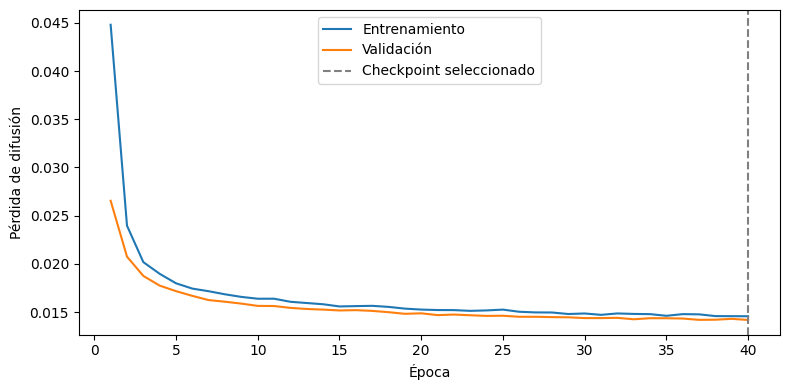

In [15]:
epochs = np.arange(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(8, 4))
plt.plot(epochs, history["train_loss"], label="Entrenamiento")
plt.plot(epochs, history["val_loss"], label="Validación")
plt.axvline(best_epoch, linestyle="--", color="gray", label="Checkpoint seleccionado")
plt.xlabel("Época")
plt.ylabel("Pérdida de difusión")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Evaluación cualitativa

La primera cuadrícula muestra la máscara de test, la cara RGB generada y su foto real. Las siguientes pruebas separan dos preguntas. Cuánta variedad obtiene el modelo para una misma máscara y cuánto cambia la cara cuando se modifica un rasgo.

In [16]:
@torch.inference_mode()
def generate(model, mask_array, seed=SEED, steps=SAMPLE_STEPS, batch_size=SAMPLE_BATCH_SIZE):
    # Entrada uint8: (N, H, W, 8). Salida uint8 RGB: (N, H, W, 3).
    model.eval()
    rng = torch.Generator(device=model.device).manual_seed(seed)
    output = np.empty((len(mask_array), IMG_SIZE, IMG_SIZE, IMAGE_CHANNELS), dtype=np.uint8)
    for start in range(0, len(mask_array), batch_size):
        batch = torch.from_numpy(np.ascontiguousarray(mask_array[start:start + batch_size]))
        batch = batch.permute(0, 3, 1, 2).to(model.device, dtype=torch.float32).div_(255)
        faces = model.sample(mask=batch, generator=rng, steps=steps)
        faces = faces.permute(0, 2, 3, 1).mul(255).round().to(torch.uint8).cpu().numpy()
        output[start:start + len(faces)] = faces
    return output

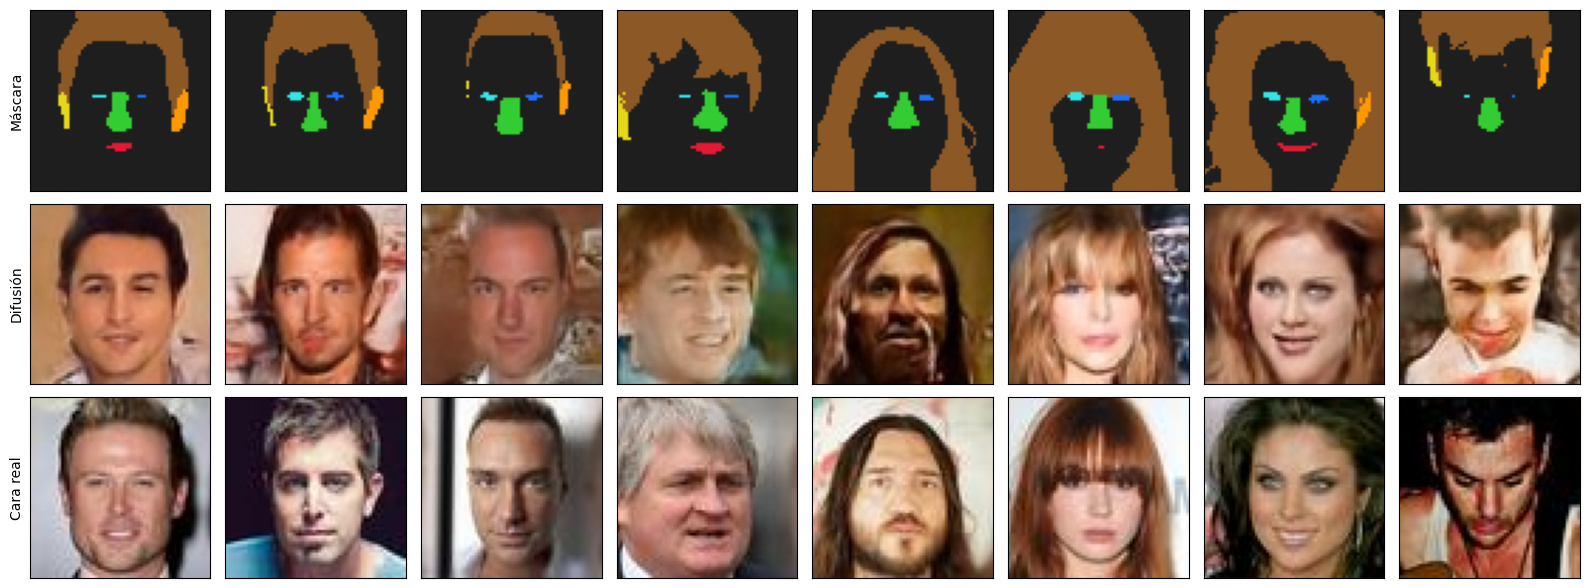

In [17]:
show_idx = np.random.default_rng(SEED).choice(len(mask_test), size=8, replace=False)
show_masks = mask_test[show_idx]
generated = generate(diffusion, show_masks, seed=SEED)
show_grid(
    [[mask_to_color(mask) for mask in show_masks], generated, img_test[show_idx]],
    ["Máscara", "Difusión", "Cara real"],
)

### 5.1 Diversidad con una misma máscara

Cada columna de generación cambia la semilla. Observa si varían el color, la iluminación y las texturas mientras la posición de los rasgos sigue la misma máscara.

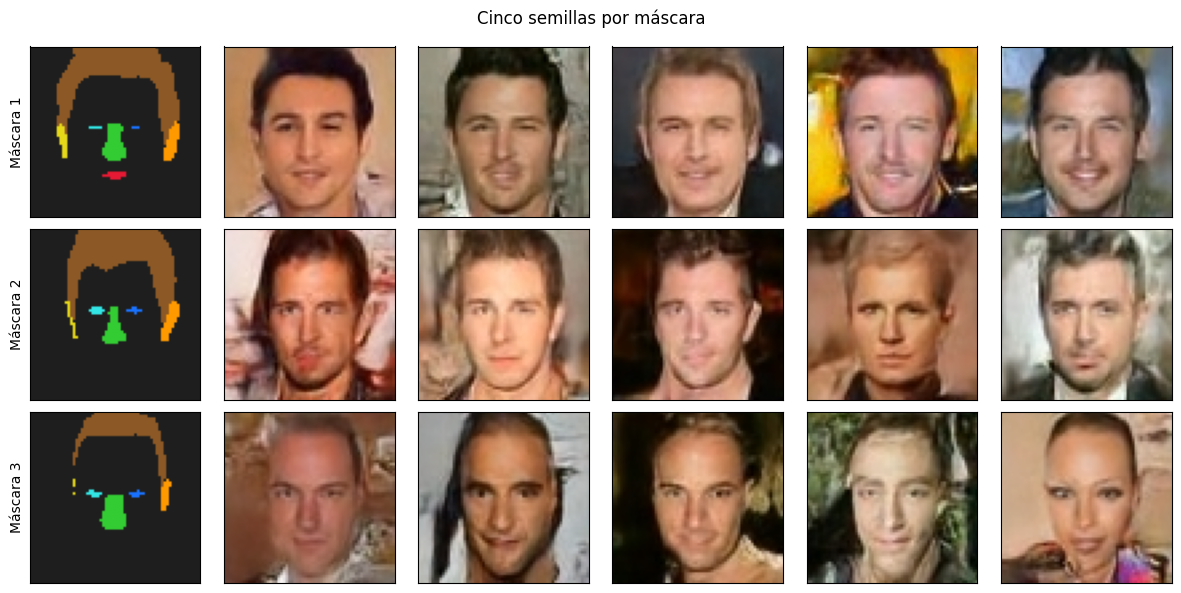

Desviación típica media por píxel: 0.1551 en escala [0, 1]


In [18]:
chosen = show_masks[:3]
variants = np.stack([generate(diffusion, chosen, seed=SEED + i) for i in range(5)], axis=1)
rows = [[mask_to_color(mask), *faces] for mask, faces in zip(chosen, variants)]
show_grid(rows, [f"Máscara {i + 1}" for i in range(len(rows))], "Cinco semillas por máscara")
diversity_std = float(variants.astype(np.float32).std(axis=1).mean() / 255)
print(f"Desviación típica media por píxel: {diversity_std:.4f} en escala [0, 1]")

### 5.2 Edición de máscaras con semilla fija

Cada columna muestra la máscara original o una edición. Se reinicia la misma semilla para cada generación para controlar tanto el ruido inicial como el ruido añadido durante el muestreo.

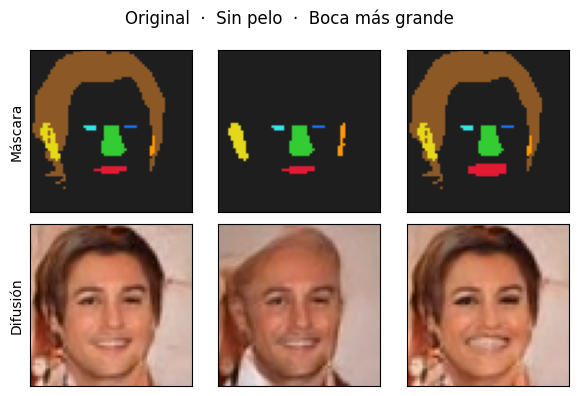

In [19]:
hair = CLASSES.index("hair")
mouth = CLASSES.index("mouth")
eligible = (mask_test[..., hair].max(axis=(1, 2)) > 127) & (mask_test[..., mouth].max(axis=(1, 2)) > 127)
if eligible.any():
    original = mask_test[np.flatnonzero(eligible)[0]]
    no_hair = original.copy()
    no_hair[..., hair] = 0
    bigger_mouth = original.copy()
    bigger_mouth[..., mouth] = cv2.dilate(original[..., mouth], np.ones((3, 3), dtype=np.uint8))
    edits = [original, no_hair, bigger_mouth]
    edited_faces = [generate(diffusion, mask[None], seed=SEED)[0] for mask in edits]
    show_grid(
        [[mask_to_color(mask) for mask in edits], edited_faces],
        ["Máscara", "Difusión"], "Original  ·  Sin pelo  ·  Boca más grande",
    )
else:
    print("No se encontró una máscara de test con pelo y boca para esta demostración.")

## 6. Evaluación cuantitativa

Calculamos **FID y KID** con características de Inception-v3 sobre las caras RGB generadas y las fotos RGB de test. La comparación entre fotos reales de entrenamiento y test sirve de referencia.

También calculamos **L1, SSIM y PSNR** respecto a la foto emparejada. Estas métricas penalizan diferencias de color o textura con esa foto, incluso si la cara generada también es plausible.

In [20]:
@torch.inference_mode()
def image_metrics(model, real, masks, train_reference):
    from torchmetrics.functional.image import structural_similarity_index_measure
    from torchmetrics.image.fid import FrechetInceptionDistance
    from torchmetrics.image.kid import KernelInceptionDistance

    n = len(real)
    if n < 2:
        raise ValueError("FID y KID necesitan al menos dos imágenes por conjunto.")
    fid = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(DEVICE)
    kid = KernelInceptionDistance(
        feature=2048, subset_size=min(n, KID_SUBSET_SIZE),
        reset_real_features=False,
    ).to(DEVICE)

    def update(images, is_real):
        for start in range(0, len(images), METRIC_BATCH_SIZE):
            batch = torch.from_numpy(np.ascontiguousarray(images[start:start + METRIC_BATCH_SIZE]))
            rgb = batch.permute(0, 3, 1, 2).to(DEVICE)
            fid.update(rgb, real=is_real)
            kid.update(rgb, real=is_real)

    def score(images):
        fid.reset()
        kid.reset()
        update(images, False)
        # Mantiene comparables las selecciones de subconjuntos KID entre repeticiones.
        devices = [DEVICE.index or torch.cuda.current_device()] if DEVICE.type == "cuda" else []
        with torch.random.fork_rng(devices=devices):
            torch.manual_seed(SEED)
            kid_mean, kid_std = kid.compute()
        return {"fid": fid.compute().item(), "kid": kid_mean.item(), "kid_subset_std": kid_std.item()}

    def paired(images):
        totals = np.zeros(3)
        for start in range(0, n, METRIC_BATCH_SIZE):
            g = torch.from_numpy(images[start:start + METRIC_BATCH_SIZE]).permute(0, 3, 1, 2).to(DEVICE)
            r = torch.from_numpy(real[start:start + METRIC_BATCH_SIZE]).permute(0, 3, 1, 2).to(DEVICE)
            g, r = g.float().div(255), r.float().div(255)
            error = g - r
            l1 = error.abs().flatten(1).mean(dim=1)
            mse = error.square().flatten(1).mean(dim=1)
            psnr = -10 * mse.clamp_min(1e-12).log10()
            ssim = structural_similarity_index_measure(g, r, data_range=1.0, reduction="none")
            totals += [l1.sum().item(), ssim.sum().item(), psnr.sum().item()]
        return dict(zip(("l1", "ssim", "psnr"), (totals / n).tolist()))

    update(real, True)
    reference = score(train_reference)
    runs = []
    for i in range(N_EVAL_REPEATS):
        images = generate(model, masks, seed=SEED + i)
        runs.append({"seed": SEED + i, **score(images), **paired(images)})
    summary = {}
    for name in ("fid", "kid", "l1", "ssim", "psnr"):
        values = [run[name] for run in runs]
        if values:
            summary[name] = {
                "mean": float(np.mean(values)),
                "std_across_runs": float(np.std(values, ddof=1)) if len(values) > 1 else None,
            }
    return {"n": n, "real_vs_real": reference, "runs": runs, "summary": summary}


test_results = None
if RUN_TEST_METRICS:
    n_eval = len(img_test) if N_TEST_METRICS is None else min(N_TEST_METRICS, len(img_test))
    test_results = image_metrics(
        diffusion, img_test[:n_eval], mask_test[:n_eval], img_train[:n_eval],
    )
    print(json.dumps(test_results, indent=2))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 126MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


{
  "n": 128,
  "real_vs_real": {
    "fid": 65.3226089477539,
    "kid": -0.0007506489637307823,
    "kid_subset_std": 0.0005003477563150227
  },
  "runs": [
    {
      "seed": 1234,
      "fid": 73.38451385498047,
      "kid": 0.011505073867738247,
      "kid_subset_std": 0.0010850492399185896,
      "l1": 0.24272681772708893,
      "ssim": 0.27006080746650696,
      "psnr": 10.523739099502563
    }
  ],
  "summary": {
    "fid": {
      "mean": 73.38451385498047,
      "std_across_runs": null
    },
    "kid": {
      "mean": 0.011505073867738247,
      "std_across_runs": null
    },
    "l1": {
      "mean": 0.24272681772708893,
      "std_across_runs": null
    },
    "ssim": {
      "mean": 0.27006080746650696,
      "std_across_runs": null
    },
    "psnr": {
      "mean": 10.523739099502563,
      "std_across_runs": null
    }
  }
}


### 6.1 Guardado de resultados

El archivo JSON guarda la configuración, el historial de pérdidas y los resultados de las pruebas ejecutadas.

In [ ]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
metrics = {
    "split": {"train": len(img_train), "val": len(img_val), "test": len(img_test)},
    "config": {**MODEL_CONFIG, "seed": SEED, "sampling_steps": SAMPLE_STEPS},
    "checkpoint": {"epoch": best_epoch, "val_loss": best_val_loss},
    "history": history,
    "test": test_results,
    "diversity_pixel_std": diversity_std,
    "nearest_train_mean_rmse": float(nearest_rmse.mean()),
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(METRICS_PATH)

## 7. Conclusiones

Entrenamos durante 40 épocas un modelo de difusión condicional que genera rostros RGB de 64×64 a partir de ocho máscaras binarias de CelebAMask. La pérdida de validación bajó de 0,02655 en la primera época a 0,01419 en la época 40, cuyo checkpoint se utilizó para la evaluación. La mayor reducción se produjo al comienzo y las mejoras fueron más pequeñas en las últimas épocas.

En los ejemplos de test, los rostros generados suelen conservar la posición general de los rasgos y la silueta del pelo. Al cambiar la semilla para una misma máscara, varían el color, la iluminación y el fondo. En las tres máscaras probadas con cinco semillas cada una, la desviación típica media por píxel fue de 0,1551 en la escala [0, 1]. En el ejemplo de edición con semilla fija, eliminar la región del pelo produjo un rostro casi calvo y ampliar la región de la boca dio lugar a una sonrisa más ancha. Estos ejemplos muestran que la máscara guía tanto la estructura general del rostro como algunos cambios locales.

En la evaluación de **128 muestras de test** con la semilla 1234, el modelo obtuvo un **FID de 73,38** y un **KID de 0,01151**. La referencia entre imágenes reales de entrenamiento y de test dio un FID de 65,32 y un KID de −0,00075, cercano a cero. La diferencia en ambas métricas indica que, en esta evaluación, las imágenes generadas todavía se apartan de la distribución de las fotografías reales. El tamaño de la muestra y el uso de una sola semilla limitan la interpretación de estos valores.

La comparación con las fotos emparejadas obtuvo un **L1 de 0,2427**, un **SSIM de 0,2701** y un **PSNR de 10,52 dB**. Estas métricas reflejan diferencias con la fotografía concreta, especialmente porque la máscara deja indeterminados aspectos como el color y la iluminación. Para comprobar si las métricas se mantienen y medir con más precisión la fidelidad a la máscara, sería útil ampliar la evaluación a más imágenes y semillas e incorporar una medida de coincidencia por rasgo, como la IoU.

## Licencia del código original

El aviso siguiente corresponde a la implementación de `simple_diffusion.py` de Phil Wang (lucidrains).

```text
MIT License

Copyright (c) 2020 Phil Wang

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```